## Desafio variable aleatoria II

In [396]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import random
from scipy.stats import norm, probplot


In [397]:
df=pd.read_csv('baby.csv', index_col='Unnamed: 0')
df.head()

,Birth.Weight,Gestational.Days,Maternal.Age,Maternal.Height,Maternal.Pregnancy.Weight,Maternal.Smoker
1,120,284,27,62,100,False
2,113,282,33,64,135,False
3,128,279,28,64,115,True
4,108,282,23,67,125,True
5,136,286,25,62,93,False


In [398]:
print('Nulos por columna')

print(df.isna().sum())
print(f'Cantidad de duplicados: {df.duplicated().sum()}')

Nulos por columna
Birth.Weight                 0
Gestational.Days             0
Maternal.Age                 0
Maternal.Height              0
Maternal.Pregnancy.Weight    0
Maternal.Smoker              0
dtype: int64
Cantidad de duplicados: 0


In [399]:
df.dtypes

Birth.Weight                 int64
Gestational.Days             int64
Maternal.Age                 int64
Maternal.Height              int64
Maternal.Pregnancy.Weight    int64
Maternal.Smoker               bool
dtype: object

In [400]:
df.describe()

,Birth.Weight,Gestational.Days,Maternal.Age,Maternal.Height,Maternal.Pregnancy.Weight
count,1174.000000,1174.000000,1174.000000,1174.000000,1174.000000
mean,119.462521,279.101363,27.228279,64.049404,128.478705
std,18.328671,16.010305,5.817839,2.526102,20.734282
min,55.000000,148.000000,15.000000,53.000000,87.000000
25%,108.000000,272.000000,23.000000,62.000000,114.250000
50%,120.000000,280.000000,26.000000,64.000000,125.000000
75%,131.000000,288.000000,31.000000,66.000000,139.000000
max,176.000000,353.000000,45.000000,72.000000,250.000000


Considera los pesos de los bebés. ¿Se puede decir que siguen una distribución
normal? Justifica tu respuesta creando los gráficos y modelos necesarios.


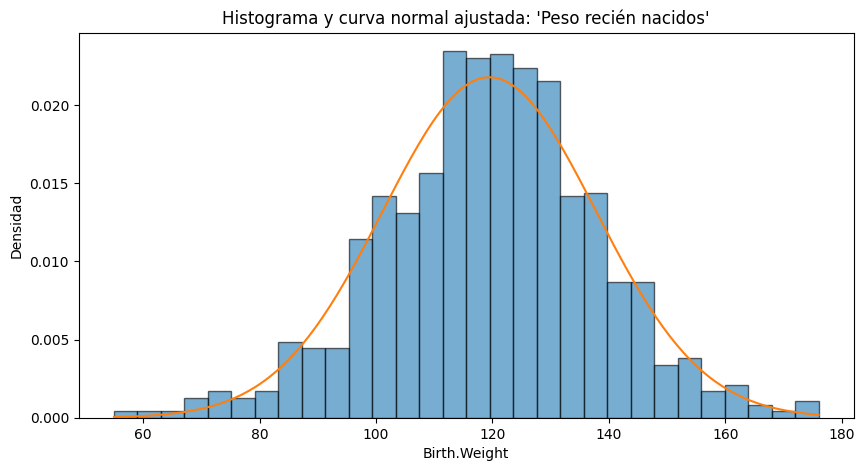

In [401]:
mu = df['Birth.Weight'].mean()
sigma = df['Birth.Weight'].std()

# Histograma + curva normal
x = np.linspace(df['Birth.Weight'].min(), df['Birth.Weight'].max(), 200)
y = norm.pdf(x, mu, sigma)

plt.figure(figsize=(10, 5))
plt.hist(df['Birth.Weight'], bins=30, density=True, alpha=0.6, edgecolor="black")
plt.plot(x, y)
plt.title("Histograma y curva normal ajustada: 'Peso recién nacidos'")
plt.xlabel('Birth.Weight')
plt.ylabel("Densidad")
plt.show()

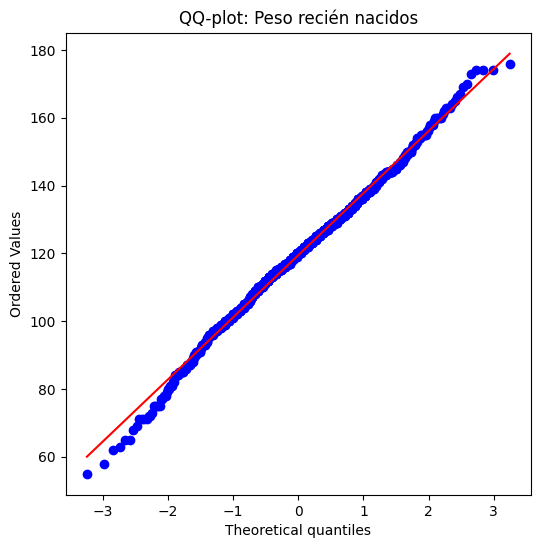

In [402]:
# QQ-plot
plt.figure(figsize=(6, 6))
probplot(df['Birth.Weight'], dist="norm", plot=plt)
plt.title("QQ-plot: Peso recién nacidos")
plt.show()

In [403]:
# La variable Birth.Weight presenta un comportamiento cercano a una distribución normal.
# El histograma muestra una forma aproximadamente simétrica y un buen ajuste a la curva normal teórica. 
# Además, en el QQ-Plot la mayoría de los puntos se ubican sobre la recta de referencia,
# observándose desviaciones menores únicamente en las colas de la distribución. 
# Esto indica que el supuesto de normalidad es razonable para esta variable.

 Considerando lo anterior, verifica el modelo de distribución normal de los pesos para
5 valores diferentes. Compara con los datos reales.


In [404]:
valores = [
    df['Birth.Weight'].quantile(0.10),
    df['Birth.Weight'].quantile(0.25),
    df['Birth.Weight'].quantile(0.50),
    df['Birth.Weight'].quantile(0.75),
    df['Birth.Weight'].quantile(0.90)]

comparacion = []

for valor in valores:
    prob_real = (df['Birth.Weight'] <= valor).mean()
    prob_modelo = norm.cdf(valor, loc=mu, scale=sigma)
    
    comparacion.append({
        "valor": valor,
        "P_real(X <= valor)": prob_real,
        "P_normal(X <= valor)": prob_modelo,
        "diferencia": abs(prob_real - prob_modelo)
    })

pd.DataFrame(comparacion)

,valor,P_real(X <= valor),P_normal(X <= valor),diferencia
0,97.0,0.105622,0.110186,0.004564
1,108.0,0.252129,0.265858,0.013729
2,120.0,0.516184,0.511697,0.004487
3,131.0,0.761499,0.735482,0.026018
4,142.0,0.900341,0.890582,0.009759


In [405]:
# Se compararon 5 valores diferentes ubicados en distintos tramos y se puede concluir que,
# la distribuición normal representa bien los datos, dado que todas las diferencias entre
# valores reales y de la curva normal son pequeñas, siendo la distribuición normal una aproximación util.

Compara los pesos de los bebés de madres fumadoras y no fumadoras. ¿Qué
diferencias existen? Explica y construye los modelos correspondientes.


In [406]:
madres_fumadoras=df[df['Maternal.Smoker']==True]['Birth.Weight']
madres_no_fumadoras=df[df['Maternal.Smoker']==False]['Birth.Weight']

def funcion_D(df):
    mu=df.mean()
    sigma=df.std()
    min=df.min()
    max=df.max()
    x = np.linspace(min,max)
    y = norm.pdf(x, mu, sigma)
    return(x,y)

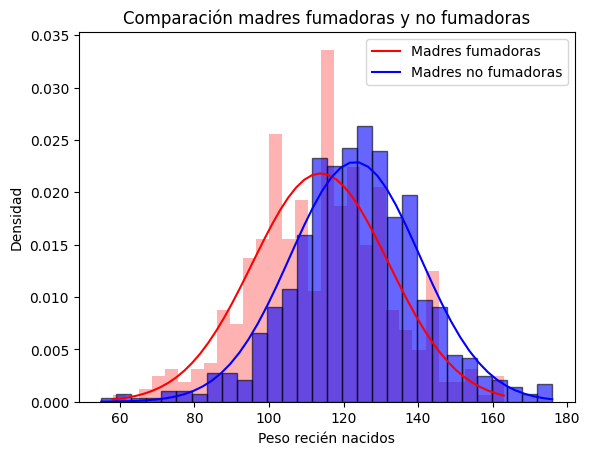

In [407]:
x, y = funcion_D(madres_fumadoras)
plt.plot(x,y,color='red', label='Madres fumadoras')
x, y = funcion_D(madres_no_fumadoras)
plt.plot(x,y,color='blue', label='Madres no fumadoras')

plt.hist(madres_fumadoras,bins=30,alpha=0.3,color='red',density=True)
plt.hist(madres_no_fumadoras,bins=30,alpha=0.6,color='blue',density=True,edgecolor='black')

plt.legend()
plt.xlabel('Peso recién nacidos')
plt.ylabel('Densidad')
plt.title('Comparación madres fumadoras y no fumadoras')
plt.show()

In [408]:
# Los gráficos de comparación muestran diferencias en el peso de los recién nacidos según si la madre es fumadora o no.
# En el caso de las madres no fumadoras, se observa una distribución del peso de los recién nacidos con un comportamiento aproximadamente normal.
# El peso de estos ultimos, es visiblemente mayor en comparación con el de los bebés de madres fumadoras.
# Si se desea predecir el peso de un recién nacido de madre fumadora, la estimación resulta más incierta, 
# dado que la distribución presenta oscilaciones más inestables y se aleja del comportamiento de una curva normal,
# en contraste con la distribución de los bebés de madres no fumadoras.

 Calcula la probabilidad de que una madre escogida al azar fume.


In [409]:
p_madre_fumadora=sum(df['Maternal.Smoker']== True)/len(df)

print(f'La probabilidad de que la madre sea fumadora es del: {round((p_madre_fumadora)*100,2)}%')

La probabilidad de que la madre sea fumadora es del: 39.1%


A partir del valor anterior, construye un modelo de distribución binomial que
modele el experimento correspondiente a escoger 5 madres al azar y observar
cuántas fuman.


In [410]:
print(f'Al escoger 5 madres al azar se obtienen: {np.random.binomial(5,p_madre_fumadora,size=1)} madres fumadoras')


Al escoger 5 madres al azar se obtienen: [3] madres fumadoras


Utilizando este modelo, simula 1000 muestras de tamaño 8, y calcula sus medias
muestrales.


In [411]:
medias_bi=[]
for i in range(1000):
    medias_bi.append(np.mean(np.random.binomial(5,p_madre_fumadora, size=8)))


Utilizando los datos directamente, extrae 1000 muestras de tamaño 8 y calcula
sus respectivas medias muestrales.

In [412]:
medias_reales = []
for i in range(1000):
    muestra = []
    for j in range(8):
        conteo_fumadoras = (df['Maternal.Smoker'].sample(n=5, replace=True).sum())
        muestra.append(conteo_fumadoras)
    medias_reales.append(np.mean(muestra))

compara gráficamente los resultados obtenidos anteriormente.
verifica el teorema del límite central, considerando las muestras de datos reales y
las simuladas con el modelo binomial.
construye un modelo de distribución normal derivado del modelo binomial, y
grafícalo junto a los anteriores para comparar. Concluye.



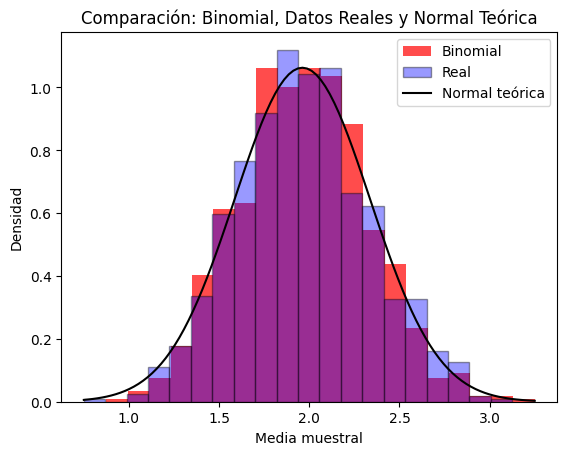

In [413]:
mu = np.mean(medias_bi)
sigma = np.std(medias_bi)

minimo = min(min(medias_bi), min(medias_reales))
maximo = max(max(medias_bi), max(medias_reales))

# Construcción de curva normal
x = np.linspace(minimo, maximo, 100)
pdf = norm.pdf(x, loc=mu, scale=sigma)

# Construcción de histogramas
plt.hist(medias_bi, bins=20, density=True, alpha=0.7, color='red', label='Binomial')
plt.hist(medias_reales, bins=20, density=True, alpha=0.4, color='blue', edgecolor='black', label='Real')

# Curva normal
plt.plot(x, pdf,color='black', label='Normal teórica')

plt.xlabel('Media muestral')
plt.ylabel('Densidad')
plt.title('Comparación: Binomial, Datos Reales y Normal Teórica')
plt.legend()
plt.show()

In [414]:
# Los histogramas presentan una forma muy similar.
# Ambas distribuciones se concentran principalmente entre valores cercanos a 1.5 y 2.5, 
# lo que indica que el modelo binomial representa adecuadamente la cantidad promedio de madres fumadoras observada en los datos.

In [415]:
# Se observa que tanto las medias muestrales simuladas como las obtenidas de los datos reales
# presentan una forma aproximadamente simétrica y acampanada. 
# Además, la curva normal ajustada sigue la forma de ambos histogramas, 
# especialmente en la zona central donde se concentra la mayor cantidad de observaciones. 
# La gran superposición entre las distribuciones binomial y real indica que la probabilidad 
# estimada de que una madre sea fumadora permite modelar adecuadamente el fenómeno observado en los datos.
# Estos resultados entregan evidencia a favor del TLC y muestran que el modelo binomial construido es consistente con los datos reales.